# Signal Timing Optimization

Generate adaptive signal timing recommendations based on traffic state.

In [1]:
import sys
sys.path.append("../src")
import pandas as pd
from optimize_signals import optimize_intersection_schedule, adaptive_change_rate

df = pd.read_csv("../data/simulated_traffic_data.csv", parse_dates=["timestamp"])
schedule = optimize_intersection_schedule(df, intersection_id=1)
schedule.head(10)

,timestamp,traffic_state,vehicle_count,recommended_green_seconds,timing_adjustment
0,2026-01-01 00:00:00,Free Flow,17,30,-15
1,2026-01-01 00:15:00,Free Flow,8,30,-15
2,2026-01-01 00:30:00,Free Flow,6,30,-15
3,2026-01-01 00:45:00,Free Flow,13,30,-15
4,2026-01-01 01:00:00,Free Flow,23,30,-15
5,2026-01-01 01:15:00,Free Flow,5,30,-15
6,2026-01-01 01:30:00,Free Flow,9,30,-15
7,2026-01-01 01:45:00,Free Flow,13,30,-15
8,2026-01-01 02:00:00,Free Flow,13,30,-15
9,2026-01-01 02:15:00,Free Flow,0,30,-15


## How often adaptive timing acts

Share of 15-minute intervals where the adaptive plan picks a different green time than a fixed 45s cycle. This is not a measured congestion reduction.

In [2]:
rate = adaptive_change_rate(df)
print(f"Intervals where adaptive timing differs from fixed 45s: {rate}%")

Intervals where adaptive timing differs from fixed 45s: 72.8%


## Visualize recommended timing distribution

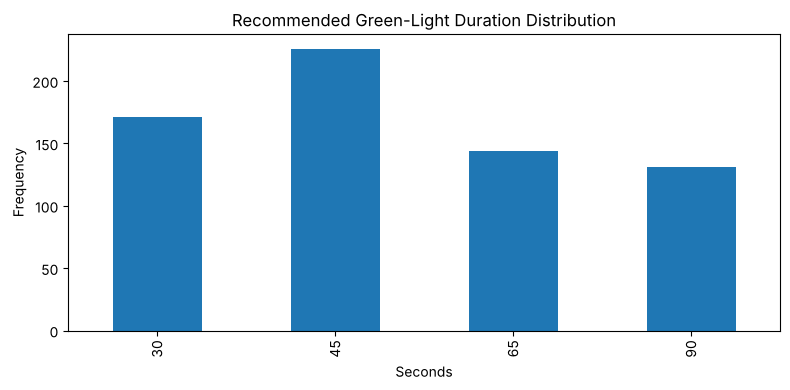

In [3]:
import matplotlib.pyplot as plt
schedule["recommended_green_seconds"].value_counts().sort_index().plot(kind="bar", figsize=(8,4))
plt.title("Recommended Green-Light Duration Distribution")
plt.xlabel("Seconds")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()